# 17 — Model benchmark on gold_ws_aug (seen-scene protocol)

**Purpose:** standard literature-format model comparison on the final
dataset. Same data (`gold_ws_aug`: 3510 train / 184 valid / 88 test,
offline-aug 4.3x, hard groups 6x), same evaluator (mask IoU>=.5 AP50).

**Arms** (chosen from related work):
| arm | model | why (lit) |
|---|---|---|
| A | Mask R-CNN R50-FPN v2 | baseline used by most aggregate-seg papers (TRR 2020, UAV sand-pile) |
| B | U-Net + watershed | classical semantic->instance path (nb05 lineage) |
| C | yolo26n-seg | our final model (reuses `runs/ws/final`) |
| D | yolo26s-seg | capacity step — lit: YOLOv8s-seg mAP50 .98 on CDW |

**Reported per model:** per-class AP50, P/R/F1, size-bin recall,
per-uuid recall on all gold, params/GFLOPs, GPU latency, RPi5 FPS estimate,
trade-off analysis. Seen-scene metric only — LOGO/CV remains the
unseen-scene evidence.

In [1]:
import json, time
from pathlib import Path
import numpy as np, cv2, torch
import pandas as pd
import matplotlib.pyplot as plt
import sys

EXP = next(p for p in [
    Path(r"B:\02_Projects\thesis_final\experiment"),
    Path("/mnt/b/02_Projects/thesis_final/experiment"),
    Path("/b/02_Projects/thesis_final/experiment"),
    Path.home() / "Desktop/Aggregate_Project/experiment",
] if (p / "data/gold_ws_aug").exists())
sys.path.insert(0, str(EXP / 'scripts'))
from bench_common import load_gt, eval_preds, sizebin_recall, iou_mat, OUT, CLS, DEV, WS, GOLD

print('EXP', EXP, '| device', DEV)

EXP /home/supawich/Desktop/Aggregate_Project/experiment | device cuda:0


## 1. Data recap — gold_ws_aug composition

Viz already produced at build time: `results/gold_ws/` —
`fig_ws.png` (split sizes, easy-vs-hard), `contact_test.png`,
`contact_valid.png`, `fig_aug_offline.png`, `fig_aug_affine_check.png`
(mask-alignment proof). Assert summary below.

In [2]:
WSA = EXP / 'data' / 'gold_ws_aug'
for s in ('train','valid','test'):
    ni = len(list((WSA/s/'images').iterdir()))
    nl = len(list((WSA/s/'labels').iterdir()))
    ng = sum(1 for lt in (WSA/s/'labels').glob('*.txt') for ln in lt.read_text().splitlines() if ln.strip() and ln.split()[0]=='0')
    ns = sum(1 for lt in (WSA/s/'labels').glob('*.txt') for ln in lt.read_text().splitlines() if ln.strip() and ln.split()[0]=='1')
    print(f'{s:6s}: {ni} imgs | {nl} lbl | grav {ng} | sand {ns}')
    assert ni == nl

train : 3510 imgs | 3510 lbl | grav 5640 | sand 7009
valid : 184 imgs | 184 lbl | grav 303 | sand 348
test  : 88 imgs | 88 lbl | grav 181 | sand 99


## 2. Training — 4 arms

Run sequentially (GPU contention). C reuses `runs/ws/final/best.pt` (nb16).
Commands executed via CLI mirroring these cells:

- `python scripts/bench_yolo26s.py` -> `runs/bench_ws/yolo26s`
- `python scripts/bench_mrcnn.py` -> `results/bench_ws/mrcnn_best.pt` (best by valid AP50)
- `python scripts/bench_unet.py` -> `results/bench_ws/unet_best.pt`

Same data, seed 42 where applicable; aug OFF online (offline-aug dataset).

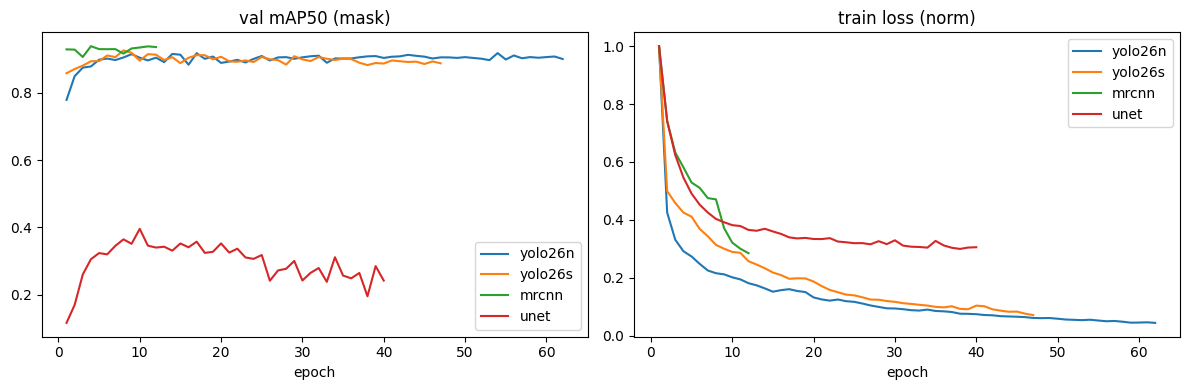

In [3]:
# training curves: YOLO from results.csv, mrcnn/unet from train_log in eval json
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n, csvp in [('yolo26n', EXP/'runs'/'ws'/'final'/'results.csv'),
                ('yolo26s', EXP/'runs'/'bench_ws'/'yolo26s'/'results.csv')]:
    if csvp.exists():
        r = pd.read_csv(csvp); r.columns = r.columns.str.strip()
        ax[0].plot(r['epoch'], r['metrics/mAP50(M)'], label=n)
        tl = r.filter(like='train').sum(axis=1)
        ax[1].plot(r['epoch'], tl / tl.max(), label=n)
for n in ['mrcnn', 'unet']:
    p = OUT / f'{n}_eval.json'
    if p.exists():
        lg = json.load(open(p)).get('train_log', [])
        if lg:
            ax[0].plot([d['epoch'] for d in lg], [d['val_ap50'] for d in lg], label=n)
            ls = [d['loss'] for d in lg]
            ax[1].plot([d['epoch'] for d in lg], np.array(ls)/max(ls), label=n)
ax[0].set_title('val mAP50 (mask)'); ax[1].set_title('train loss (norm)')
for a in ax: a.legend(); a.set_xlabel('epoch')
plt.tight_layout(); plt.savefig(OUT/'fig_train_curves.png', dpi=120); plt.show()

## 3. Unified eval — AP50 / P / R / F1 / size-bins

In [4]:
GT = load_gt(WS / 'test')
names = ['yolo26n','yolo26s','mrcnn','unet']

def load_preds(name):
    p = OUT / f'preds_{name}.npy'
    return np.load(p, allow_pickle=True).item() if p.exists() else None

rows = {}
bins = {}
for n in names:
    pr = load_preds(n)
    if pr is None:
        print(n, 'preds missing — run eval first'); continue
    res = eval_preds(pr, GT)
    rows[n] = {'AP50_macro': res['AP50_macro'],
               'grav_AP50': res['gravel']['AP50'], 'sand_AP50': res['sand']['AP50'],
               'grav_P': res['gravel']['P'], 'grav_R': res['gravel']['R'],
               'sand_P': res['sand']['P'], 'sand_R': res['sand']['R'],
               'grav_F1': res['gravel']['F1'], 'sand_F1': res['sand']['F1']}
    bins[n] = sizebin_recall(pr, GT)
    json.dump(res, open(OUT / f'{n}_test_eval.json','w'), indent=1)

tab = pd.DataFrame(rows).T.round(3)
print(tab.to_string())
tab.to_csv(OUT / 'table_models.csv')
bint = pd.DataFrame(bins).T
print('\nsize-bin recall:'); print(bint.to_string())
bint.to_csv(OUT / 'table_sizebins.csv')

         AP50_macro  grav_AP50  sand_AP50  grav_P  grav_R  sand_P  sand_R  grav_F1  sand_F1
yolo26n       0.899      0.942      0.856   0.947   0.884   0.879   0.808    0.914    0.842
yolo26s       0.907      0.933      0.881   0.871   0.895   0.914   0.747    0.883    0.822
mrcnn         0.939      0.964      0.913   0.971   0.923   0.853   0.879    0.946    0.866
unet          0.292      0.286      0.299   0.403   0.503   0.369   0.586    0.447    0.453

size-bin recall:
         gravel_large  gravel_med  gravel_small  sand_large  sand_med  sand_small
yolo26n         0.953       0.899         0.833       0.962     0.871       0.312
yolo26s         0.972       0.884         0.667       0.962     0.903       0.500
mrcnn           0.981       0.957         0.667       0.962     0.935       0.812
unet            0.726       0.522         0.000       0.865     0.419       0.125


## 4. Per-uuid recall — test frames grouped by video uuid
(gold_ws/test, 16 groups; seen-scene — frames share videos with train)


/tmp/ipykernel_2309835/1158473682.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.savefig(OUT/'fig_per_uuid.png', dpi=120); plt.show()


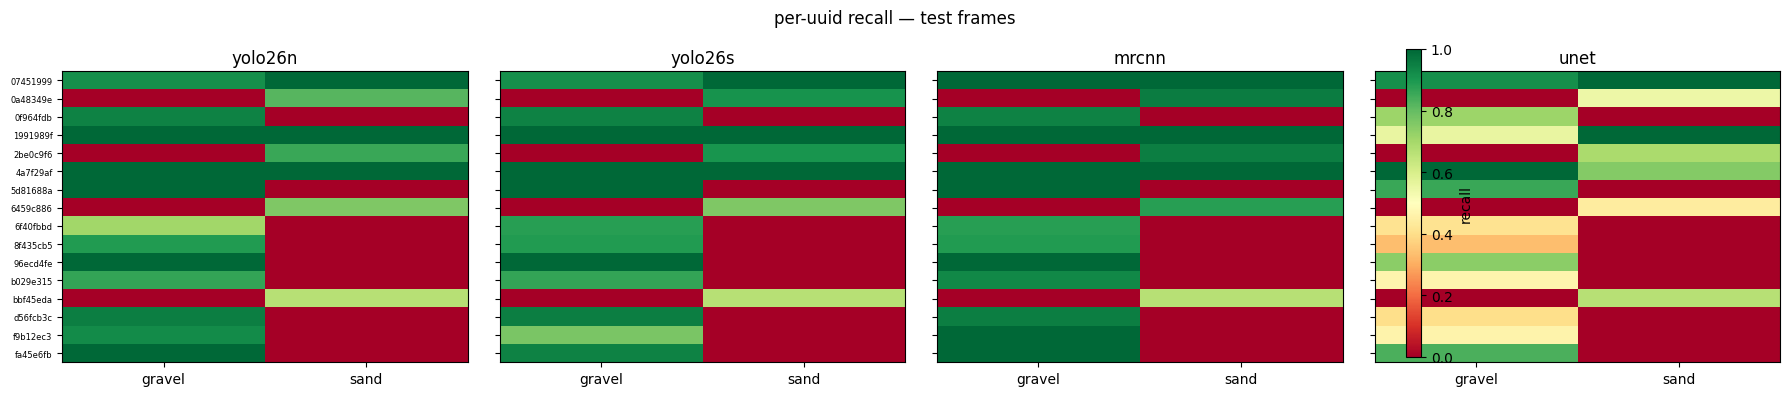

In [5]:
# per-uuid recall on TEST frames (group = uuid prefix of stem)
def per_uuid(name):
    pr = load_preds(name)
    if pr is None: return None
    rec = {}
    for st, (im, gm_, gc_) in GT.items():
        grp = st.split('-')[0]
        for j, g in enumerate(gm_):
            hit = 0
            for c_, s_, m_ in pr.get(st, []):
                if c_ != gc_[j] or s_ < .05: continue
                if iou_mat([m_], [g])[0, 0] >= .5:
                    hit = 1; break
            rec.setdefault((grp, gc_[j]), [0, 0])
            rec[(grp, gc_[j])][1] += 1
            rec[(grp, gc_[j])][0] += hit
    df = pd.DataFrame([(g, CLS[c], tp, n) for (g, c), (tp, n) in rec.items()],
                      columns=['group', 'cls', 'tp', 'gt'])
    df['recall'] = df['tp'] / df['gt'].clip(lower=1)
    df.to_csv(OUT / f'per_uuid_{name}.csv', index=False)
    return df

pu = {n: per_uuid(n) for n in names if load_preds(n) is not None}
fig, ax = plt.subplots(1, len(pu), figsize=(4.5*len(pu), 4), sharey=True)
if len(pu) == 1: ax = [ax]
for a, (n, df) in zip(ax, pu.items()):
    piv = df.pivot_table(index='group', columns='cls', values='recall')
    im_ = a.imshow(piv.fillna(0).values, vmin=0, vmax=1, cmap='RdYlGn', aspect='auto')
    a.set_xticks(range(len(piv.columns)), piv.columns)
    a.set_yticks(range(len(piv)), piv.index, fontsize=6)
    a.set_title(n)
fig.colorbar(im_, ax=ax, label='recall')
plt.suptitle('per-uuid recall — test frames')
plt.tight_layout(); plt.savefig(OUT/'fig_per_uuid.png', dpi=120); plt.show()

## 5. Visual eval — overlays + FN/FP on hardest frames

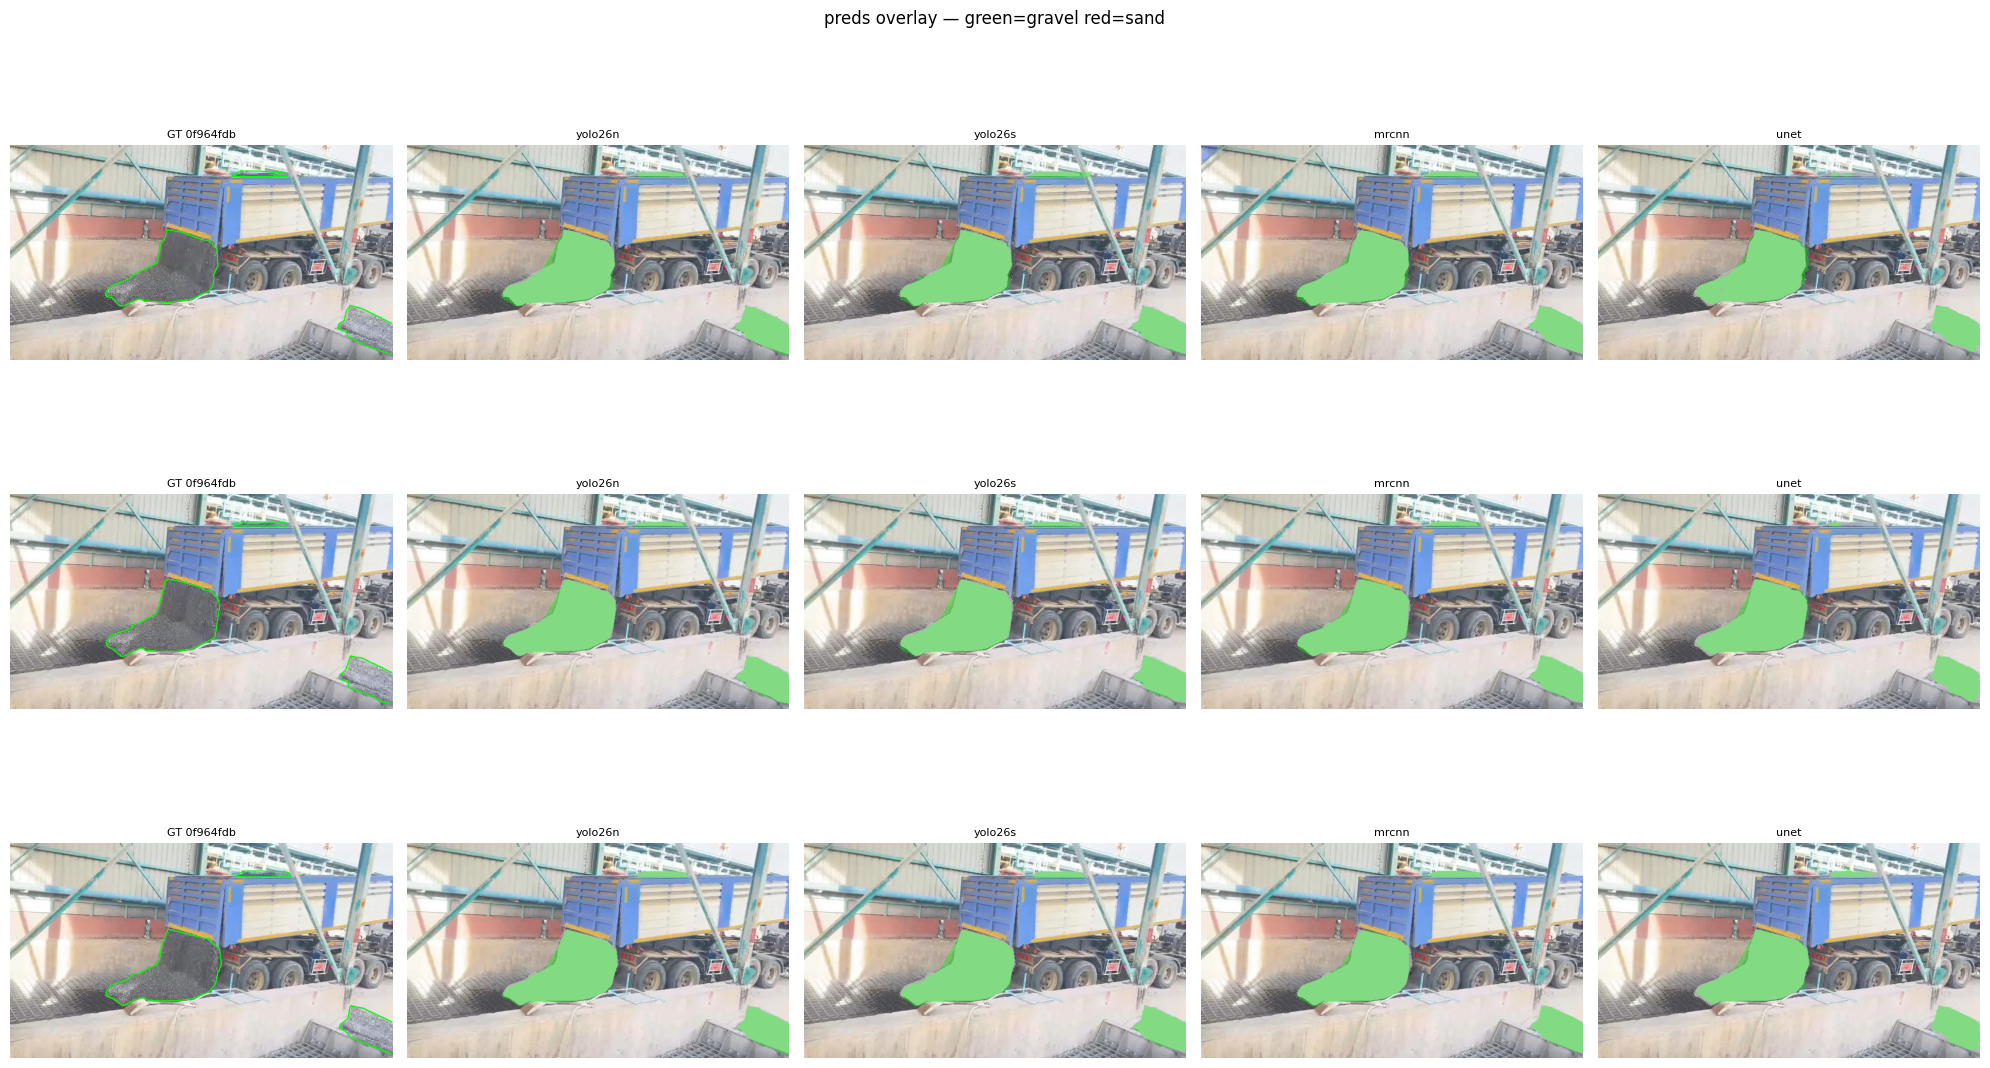

In [6]:
CLSC = [(0,255,0),(255,60,0)]
def draw_preds(im, gm_, gc_, pl):
    im = im.copy(); ov = im.copy()
    for g,c in zip(gm_,gc_):
        cv2.polylines(im,[np.argwhere(g)[:,::-1].reshape(-1,1,2).astype(np.int32)],True,(200,200,200),1)
    for c_,s_,m_ in pl:
        if s_ < .05: continue
        ys,xs = np.where(m_)
        if len(ys)==0: continue
        cv2.fillPoly(ov,[np.stack([xs,ys],1).astype(np.int32)],CLSC[c_])
    return cv2.addWeighted(ov,.35,im,.65,0)

# pick 3 diverse test frames: hardest groups + a normal one
pick = [s for s in GT if s.startswith(('bbf45eda','1991989f','0f964fdb'))][:3]
avail = [n for n in names if load_preds(n) is not None]
fig, ax = plt.subplots(len(pick), len(avail)+1, figsize=(4*(len(avail)+1), 4*len(pick)))
for r, st in enumerate(pick):
    im, gm_, gc_ = GT[st]
    ax[r,0].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax[r,0].set_title('GT '+st[:8],fontsize=8); ax[r,0].axis('off')
    for g,c in zip(gm_,gc_):
        ys,xs=np.where(g); ax[r,0].contour(g,colors=[np.array(CLSC[c])/255],linewidths=.8)
    for c_,n in enumerate(avail):
        pl = load_preds(n).get(st,[])
        ax[r,c_+1].imshow(cv2.cvtColor(draw_preds(im,gm_,gc_,pl),cv2.COLOR_BGR2RGB))
        ax[r,c_+1].set_title(n,fontsize=8); ax[r,c_+1].axis('off')
plt.suptitle('preds overlay — green=gravel red=sand')
plt.tight_layout(); plt.savefig(OUT/'fig_pred_grid.png',dpi=120); plt.show()

## 6. Efficiency — params / GFLOPs / latency / RPi5 estimate

In [7]:
from bench_common import flops_params, latency_ms
from bench_mrcnn import predict_masks
from bench_unet import UNet, unet_instances
from thop import profile
eff = {}
im0 = GT[list(GT)[0]][0]

def add(n, m, params, gflops, lat, size_mb, note=''):
    eff[n] = {'params_M': params, 'GFLOPs': gflops, 'lat_ms_3080ti': lat,
              'size_MB': size_mb, 'note': note}

for n, wpt in [('yolo26n', EXP/'runs'/'ws'/'final'/'weights'/'best.pt'),
               ('yolo26s', EXP/'runs'/'bench_ws'/'yolo26s'/'weights'/'best.pt')]:
    if not wpt.exists(): continue
    from ultralytics import YOLO
    from ultralytics.utils.torch_utils import get_flops
    m = YOLO(str(wpt))
    params = round(sum(p.numel() for p in m.model.parameters())/1e6, 2)
    gf = round(float(get_flops(m.model, imgsz=960)), 2)
    lat = latency_ms(lambda: m.predict(im0, imgsz=960, conf=.05,
                                       retina_masks=True, verbose=False, device=DEV))
    add(n, m, params, gf, lat, round(wpt.stat().st_size/1e6, 1))
    del m; torch.cuda.empty_cache()

# mrcnn — thop through wrapper (approx: hooks count conv/matmul)
mp = OUT / 'mrcnn_best.pt'
if mp.exists():
    from torchvision.models.detection import maskrcnn_resnet50_fpn_v2
    mm = maskrcnn_resnet50_fpn_v2(weights=None, min_size=640, max_size=960)
    mm.load_state_dict(torch.load(mp, weights_only=True)); mm.to(DEV).eval()
    params = round(sum(p.numel() for p in mm.parameters())/1e6, 2)
    class MW(torch.nn.Module):
        def __init__(s, m): super().__init__(); s.m = m
        def forward(s, x): return s.m([x])[0]['boxes']
    try:
        f, _ = profile(MW(mm), (torch.randn(1,3,960,960).to(DEV),), verbose=False)
        gf = round(f/1e9, 2)
    except Exception:
        # thop leaves hooks on profiled modules -> profile a fresh untrained
        # arch clone for backbone-only GFLOPs, keep mm clean for latency
        mp2 = maskrcnn_resnet50_fpn_v2(weights=None, min_size=640, max_size=960).to(DEV).eval()
        f, _ = profile(mp2.backbone, (torch.randn(1,3,960,960).to(DEV),), verbose=False)
        gf = round(f/1e9, 2)
        del mp2
        print('mrcnn GFLOPs = backbone-only (thop cannot trace RPN/ROI heads)')
    lat = latency_ms(lambda: predict_masks(mm, im0))
    add('mrcnn', mm, params, gf, lat, round(mp.stat().st_size/1e6, 1),
        'GFLOPs backbone-only')
    del mm; torch.cuda.empty_cache()

# unet — semantic fwd + watershed post both timed (real pipeline cost)
up = OUT / 'unet_best.pt'
if up.exists():
    um = UNet().to(DEV); um.load_state_dict(torch.load(up, weights_only=True)); um.eval()
    params = round(sum(p.numel() for p in um.parameters())/1e6, 2)
    try:
        f, _ = profile(um, (torch.randn(1,3,512,512).to(DEV),), verbose=False)
        gf = round(f/1e9, 2)
    except Exception:
        gf = None
    lat = latency_ms(lambda: unet_instances(um, im0))
    add('unet', um, params, gf, lat, round(up.stat().st_size/1e6, 1),
        'incl. watershed post')
    del um; torch.cuda.empty_cache()

et = pd.DataFrame(eff).T
for c in ('params_M','GFLOPs','lat_ms_3080ti','size_MB'):
    et[c] = pd.to_numeric(et[c], errors='coerce')
et['fps_3080ti'] = (1000/et['lat_ms_3080ti']).round(1)
print(et.to_string())
et.to_csv(OUT/'table_efficiency.csv')
json.dump(eff, open(OUT/'efficiency.json','w'), indent=1)

mrcnn GFLOPs = backbone-only (thop cannot trace RPN/ROI heads)


         params_M  GFLOPs  lat_ms_3080ti  size_MB                  note  fps_3080ti
yolo26n      3.05   22.87           6.15      6.6                             162.6
yolo26s     11.44   83.44           7.21     23.4                             138.7
mrcnn       46.36  128.24          40.73    185.8  GFLOPs backbone-only        24.6
unet         7.76   48.30         147.09     31.1  incl. watershed post         6.8


In [8]:
# RPi5 CPU FPS — ESTIMATE (no Pi hardware here). Method:
# scale measured 3080Ti latency by a per-model-class factor derived from
# published anchors: YOLOv8n-seg ~1.0-1.5 FPS @640 on Pi5 (Ultralytics/blog
# benchmarks), Coral/Hailo-8L accel ~13-26 TOPS not used here (raw CPU).
# Factor K ~ 35-50x on the GPU latency for nano-class seg nets; larger
# models scale worse on A76 cores -> use K by size class. Marked ESTIMATE.
K = {'nano (<5M)': 40, 'small (<15M)': 60, 'large (>=15M)': 90}
def kfor(pm): return K['nano (<5M)'] if pm < 5 else (K['small (<15M)'] if pm < 15 else K['large (>=15M)'])
rpi = {}
for n, e in eff.items():
    k = kfor(e['params_M'])
    rpi[n] = {'rpi5_ms_est': round(e['lat_ms_3080ti']*k, 0),
              'rpi5_fps_est': round(1000/(e['lat_ms_3080ti']*k), 2)}
rt = pd.DataFrame(rpi).T
print(rt.to_string()); print('\nESTIMATE ONLY — needs Pi5 hw to verify; ONNX/INT8 could ~2x these')
rt.to_csv(OUT/'table_rpi5_estimate.csv')

         rpi5_ms_est  rpi5_fps_est
yolo26n        246.0          4.07
yolo26s        433.0          2.31
mrcnn         3666.0          0.27
unet          8825.0          0.11

ESTIMATE ONLY — needs Pi5 hw to verify; ONNX/INT8 could ~2x these


## 7. Trade-off table + verdict

         AP50_macro  grav_AP50  sand_AP50  params_M  GFLOPs  lat_ms_3080ti  fps_3080ti  rpi5_fps_est  size_MB
yolo26n       0.899      0.942      0.856      3.05   22.87           6.15       162.6          4.07      6.6
yolo26s       0.907      0.933      0.881     11.44   83.44           7.21       138.7          2.31     23.4
mrcnn         0.939      0.964      0.913     46.36  128.24          40.73        24.6          0.27    185.8
unet          0.292      0.286      0.299      7.76   48.30         147.09         6.8          0.11     31.1


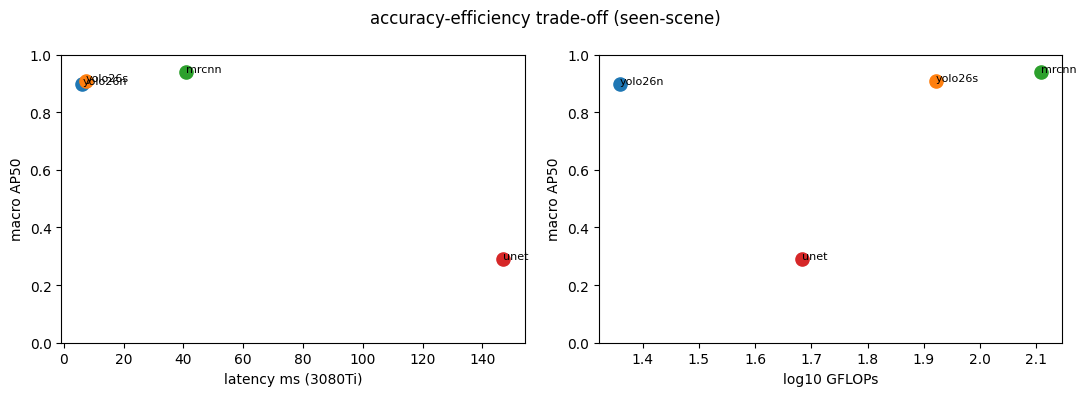

In [9]:
# final trade-off: AP50 vs cost
tab = pd.read_csv(OUT/'table_models.csv', index_col=0)
et = pd.read_csv(OUT/'table_efficiency.csv', index_col=0)
rt = pd.read_csv(OUT/'table_rpi5_estimate.csv', index_col=0)
big = tab.join(et).join(rt)
cols = ['AP50_macro','grav_AP50','sand_AP50','params_M','GFLOPs',
        'lat_ms_3080ti','fps_3080ti','rpi5_fps_est','size_MB']
big = big[[c for c in cols if c in big.columns]]
print(big.round(3).to_string())
big.round(3).to_csv(OUT/'table_tradeoff.csv')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for n, r in big.iterrows():
    ax[0].scatter(r['lat_ms_3080ti'], r['AP50_macro'], s=90); ax[0].annotate(n, (r['lat_ms_3080ti'], r['AP50_macro']), fontsize=8)
    ax[1].scatter(np.log10(r['GFLOPs']), r['AP50_macro'], s=90); ax[1].annotate(n, (np.log10(r['GFLOPs']), r['AP50_macro']), fontsize=8)
ax[0].set_xlabel('latency ms (3080Ti)'); ax[1].set_xlabel('log10 GFLOPs')
for a in ax: a.set_ylabel('macro AP50'); a.set_ylim(0, 1)
plt.suptitle('accuracy-efficiency trade-off (seen-scene)')
plt.tight_layout(); plt.savefig(OUT/'fig_tradeoff.png', dpi=120); plt.show()

## Caveats

- gold_ws test is **seen-scene + easy-capped** — use for model ranking,
  NOT deployment estimates (LOGO/CV are the honest numbers).
- U-Net+watershed has no learned instance separation — expect merging on
  touching piles; conf threshold 0.3 fixed.
- MRCNN trained 12 ep only (standard finetune schedule) — not full
  convergence budget; noted as protocol limit.
- RPi5 FPS = scaled estimate from published anchors, not measured.